# **1. INTRODUÇÃO**

Neste projeto, atuarei como analista de dados da Zuber, uma nova empresa de transporte por aplicativo que está iniciando suas operações em Chicago.

O objetivo é analisar os dados disponíveis para identificar padrões no comportamento dos passageiros, compreender suas preferências e investigar a influência de fatores externos na dinâmica das corridas.

A análise será realizada por meio de consultas a um banco de dados utilizando SQL, com foco na exploração dos dados de concorrentes e na comparação da duração média das viagens em diferentes condições climáticas.

Os resultados permitirão avaliar possíveis relações entre as condições meteorológicas e a duração das corridas, contribuindo para uma melhor compreensão do mercado de transporte por aplicativo em Chicago.

## **1.1. Dicionário de Dados**

O banco de dados reúne informações sobre corridas de táxi na cidade de Chicago, organizadas em quatro tabelas: `neighborhoods`, `cabs`, `trips` e `weather_records`.

A seguir, são apresentadas as tabelas e suas respectivas variáveis:

### Tabela `neighborhoods` — Bairros de Chicago

| Coluna | Descrição |
|---|---|
| `neighborhood_id` | Identificador único do bairro. |
| `name` | Nome do bairro. |

### Tabela `cabs` — Táxis

| Coluna | Descrição |
|---|---|
| `cab_id` | Identificador do táxi. |
| `vehicle_id` | Identificação técnica do veículo. |
| `company_name` | Nome da empresa proprietária do veículo. |

### Tabela `trips` — Corridas

| Coluna | Descrição |
|---|---|
| `trip_id` | Identificador da corrida. |
| `cab_id` | Identificador do táxi responsável pela corrida. |
| `start_ts` | Data e hora de início da corrida, com o horário arredondado para a hora. |
| `end_ts` | Data e hora de término da corrida, com o horário arredondado para a hora. |
| `duration_seconds` | Duração da corrida em segundos. |
| `distance_miles` | Distância percorrida em milhas. |
| `pickup_location_id` | Identificador do bairro de origem da corrida. |
| `dropoff_location_id` | Identificador do bairro de destino da corrida. |

### Tabela `weather_records` — Registros meteorológicos

| Coluna | Descrição |
|---|---|
| `record_id` | Identificador do registro meteorológico. |
| `ts` | Data e hora do registro, com o horário arredondado para a hora. |
| `temperature` | Temperatura registrada no momento da observação. |
| `description` | Descrição das condições meteorológicas, como chuva leve ou nuvens esparsas. |

## **1.2. Esquema do Banco de Dados**

O diagrama a seguir apresenta a estrutura do banco de dados e os relacionamentos entre as quatro tabelas: `trips`, `cabs`, `neighborhoods` e `weather_records`.

As chaves primárias (PK) identificam exclusivamente os registros de cada tabela, enquanto as chaves estrangeiras (FK) estabelecem os relacionamentos entre elas.

Na tabela `trips`, os campos `cab_id`, `pickup_location_id` e `dropoff_location_id` permitem relacionar cada corrida, respectivamente, aos dados dos táxis e aos bairros de origem e destino.

**Relacionamento com os dados meteorológicos**

Não existe uma chave estrangeira que conecte diretamente as tabelas `trips` e `weather_records`. Entretanto, é possível relacioná-las utilizando os campos temporais:

- `trips.start_ts`: data e hora de início da corrida.
- `weather_records.ts`: data e hora do registro meteorológico.

Dessa forma, a combinação dessas colunas por meio de uma operação `JOIN` permite associar as corridas às condições climáticas registradas no mesmo horário, possibilitando investigar a relação entre o clima e a duração das viagens.

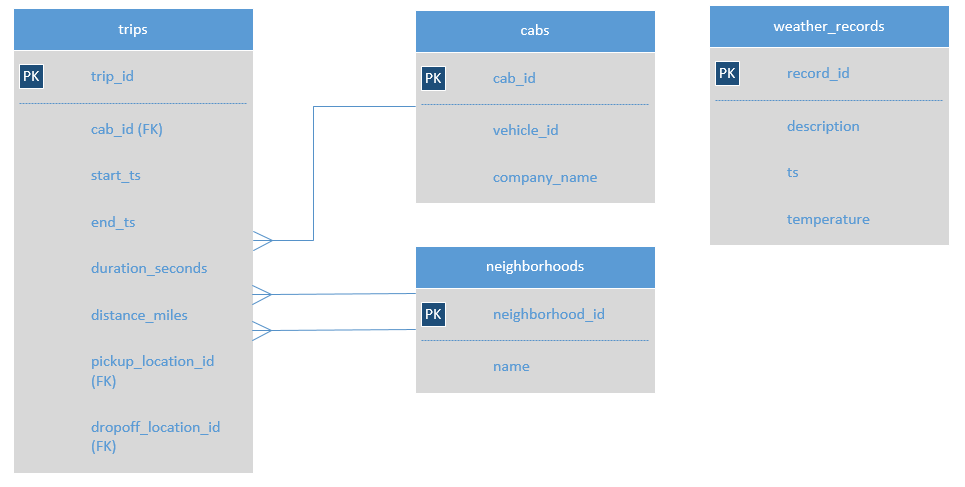

# **2. Coleta e Preparação dos Dados Meteorológicos**

Nesta etapa, será realizada a extração dos registros meteorológicos de Chicago referentes a novembro de 2017, disponibilizados na página indicada abaixo.

**Fonte dos dados:** [Chicago Weather Records — November 2017](https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html)

O objetivo é obter os dados da tabela HTML e armazená-los em um DataFrame do Pandas denominado `weather_records`.

Para identificar corretamente a tabela na página, será utilizado o parâmetro `attrs={"id": "weather_records"}` na função de leitura. Ao final, o DataFrame completo será exibido para permitir a inspeção inicial dos registros coletados.

## **2.1. Extração dos Dados Meteorológicos**

Para obter os registros meteorológicos de Chicago referentes a novembro de 2017, será realizada a extração de uma tabela disponibilizada em uma página HTML.

O código utiliza as bibliotecas `Requests`, `BeautifulSoup` e `Pandas` para acessar a página, localizar a tabela identificada pelo atributo `id="weather_records"` e extrair seus dados.

Em seguida, os cabeçalhos e registros são organizados em um DataFrame denominado `weather_records`, que será exibido integralmente para inspeção.

In [33]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html'

req = requests.get(URL)
soup = BeautifulSoup(req.text, 'lxml')
table = soup.find('table', attrs={"id": "weather_records"})

heading_table = []
for row in table.find_all('th'):
    heading_table.append(row.text)

content = []
for row in table.find_all('tr'):
    if not row.find_all('th'):
        content.append([element.text for element in row.find_all('td')])

weather_records = pd.DataFrame(content, columns=heading_table)
print(weather_records)

           Date and time Temperature       Description
0    2017-11-01 00:00:00     276.150     broken clouds
1    2017-11-01 01:00:00     275.700  scattered clouds
2    2017-11-01 02:00:00     275.610   overcast clouds
3    2017-11-01 03:00:00     275.350     broken clouds
4    2017-11-01 04:00:00     275.240     broken clouds
..                   ...         ...               ...
692  2017-11-29 20:00:00     281.340        few clouds
693  2017-11-29 21:00:00     281.690      sky is clear
694  2017-11-29 22:00:00     281.070        few clouds
695  2017-11-29 23:00:00     280.060      sky is clear
696  2017-11-30 00:00:00     278.460      sky is clear

[697 rows x 3 columns]


## **2.2. Consultas SQL**

Nesta etapa, serão realizadas consultas SQL para explorar o banco de dados da Zuber. O objetivo é analisar o volume de corridas por empresa de táxi, identificar os bairros de origem e destino e relacionar as condições meteorológicas à duração das viagens.

As atividades estão divididas em seis consultas:

**1. Volume de corridas por empresa de táxi**

Exiba o campo `company_name` e calcule a quantidade de corridas realizadas por cada empresa de táxi nos dias 15 e 16 de novembro de 2017. Nomeie o campo resultante como `trips_amount`. Apresente os resultados em ordem decrescente de quantidade de corridas.

**2. Corridas realizadas por empresas Yellow e Blue**

Calcule a quantidade de corridas realizadas entre 1º e 7 de novembro de 2017 pelas empresas de táxi cujos nomes contenham as palavras "Yellow" ou "Blue". Nomeie o campo resultante como `trips_amount` e agrupe os resultados pelo campo `company_name`.

**3. Comparação entre as principais empresas e as demais**

Entre 1º e 7 de novembro de 2017, as empresas Flash Cab e Taxi Affiliation Services foram identificadas como as mais populares. Calcule a quantidade de corridas realizadas por cada uma delas e agrupe as corridas das demais empresas em uma única categoria, denominada "Other".

Agrupe os resultados pelos nomes das empresas de táxi, nomeie o campo correspondente como `company` e a quantidade de corridas como `trips_amount`. Ordene os resultados em ordem decrescente de quantidade de corridas.

**4. Identificação dos bairros Loop e O'Hare**

Recupere, na tabela `neighborhoods`, os identificadores correspondentes aos bairros Loop e O'Hare.

**5. Classificação das condições meteorológicas**

Recupere os registros meteorológicos da tabela `weather_records` e utilize o operador `CASE` para classificar cada hora em uma das seguintes categorias:

- `Bad`: quando o campo `description` contiver as palavras `rain` ou `storm`.
- `Good`: para todas as demais condições meteorológicas.

Nomeie o campo resultante como `weather_conditions`. A tabela final deverá apresentar apenas duas colunas: `ts` (data e hora do registro) e `weather_conditions`.

**6. Relação entre condições meteorológicas e duração das corridas**

Recupere, na tabela `trips`, todas as corridas que atendam simultaneamente aos seguintes critérios:

- Início no bairro Loop (`pickup_location_id = 50`).
- Término no bairro O'Hare (`dropoff_location_id = 63`).
- Realização em um sábado.

Associe cada corrida às respectivas condições meteorológicas, utilizando o método de classificação desenvolvido na consulta anterior. Recupere também a duração de cada viagem.

Desconsidere as corridas que não possuam registros meteorológicos correspondentes.

A tabela final deverá conter as colunas na seguinte ordem:

1. `start_ts`
2. `weather_conditions`
3. `duration_seconds`

Ordene os resultados pelo campo `trip_id`.

In [34]:
# 1. Instalar e carregar a extensão ipython-sql
!pip install ipython-sql --quiet
%load_ext sql

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


In [35]:
import sqlite3

# 2. Criar uma conexão local SQLite de exemplo para o comando mágico funcionar
# Em um cenário real, você conectaria ao seu banco de dados (ex: postgresql, mysql, sqlite)
con = sqlite3.connect('zuber_database.db')

# Conectar o comando mágico a este banco de dados local
%sql sqlite:///zuber_database.db

### **2.2.1. Quantidade de Corridas por Empresa de Táxi**
A consulta tem como objetivo identificar o volume de corridas realizadas por cada empresa de táxi nos dias 15 e 16 de novembro de 2017.

Para isso, são relacionadas as tabelas trips e cabs por meio do campo cab_id. A função COUNT() contabiliza as corridas de cada empresa, enquanto GROUP BY agrupa os registros pelo nome da empresa.

O período é delimitado pela cláusula WHERE, utilizando CAST() para converter o campo start_ts para o formato de data. Por fim, os resultados são ordenados em ordem decrescente pelo número de corridas.

Código SQL

Como o Colab não possui o banco de dados original, vamos armazenar a consulta em uma variável Python para documentar o código desenvolvido na plataforma TripleTen.

In [36]:
# Consulta 1: Quantidade de corridas por empresa de táxi
# Período: 15 e 16 de novembro de 2017

sql_query_1 = """
SELECT
    c.company_name,
    COUNT(t.trip_id) AS trips_amount
FROM
    trips t
    INNER JOIN cabs c ON t.cab_id = c.cab_id
WHERE
    CAST(t.start_ts AS date) BETWEEN '2017-11-15' AND '2017-11-16'
GROUP BY
    c.company_name
ORDER BY
    trips_amount DESC;
"""

**Resultado da consulta**

O resultado disponibilizado pela TripleTen está no arquivo moved_project_sql_result_01.csv, que contém 64 empresas de táxi e suas respectivas quantidades de corridas.

Para apresentar os dados no notebook, utilize uma nova célula Python:

In [37]:
import pandas as pd

result_1 = pd.read_csv("moved_project_sql_result_01.csv")

display(result_1)

,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasin,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299
...,...,...
59,4053 - 40193 Adwar H. Nikola,7
60,2733 - 74600 Benny Jona,7
61,5874 - 73628 Sergey Cab Corp.,5
62,"2241 - 44667 - Felman Corp, Manuel Alonso",3


**Análise**

A Flash Cab apresentou o maior volume de corridas no período analisado, com 19.558 registros, seguida pela Taxi Affiliation Services, com 11.422 corridas.

A diferença entre as duas empresas foi de 8.136 corridas, evidenciando a liderança da Flash Cab em relação às demais empresas no período.

Os resultados também mostram uma concentração expressiva de corridas entre as cinco empresas com maior volume, enquanto as demais apresentam quantidades progressivamente menores.

Essa distribuição permite identificar os principais concorrentes da Zuber no mercado de transporte por aplicativo em Chicago.

### **2.2.2. Corridas Realizadas pelas Empresas Yellow e Blue**

Nesta etapa, serão analisadas as corridas realizadas pelas empresas de táxi Yellow e Blue em Chicago, no período de 1º a 7 de novembro de 2017.

O objetivo é identificar o volume de corridas de cada empresa durante o período, permitindo comparar sua participação na operação do mercado de transporte por táxi. Para isso, serão utilizadas consultas SQL para filtrar as empresas pelo nome e contabilizar suas respectivas corridas.

In [39]:
# Consulta 2: Quantidade de corridas das empresas Yellow e Blue
# Período: 1º a 7 de novembro de 2017

sql_query_2 = """
SELECT
    c.company_name,
    COUNT(t.trip_id) AS trips_amount
FROM
    trips t
    INNER JOIN cabs c ON t.cab_id = c.cab_id
WHERE
    CAST(t.start_ts AS date) BETWEEN '2017-11-01' AND '2017-11-07'
    AND (
        c.company_name LIKE '%Yellow%'
        OR c.company_name LIKE '%Blue%'
    )
GROUP BY
    c.company_name;
"""

In [40]:
import pandas as pd

# Resultado da consulta SQL 2: Empresas Yellow e Blue

result_2 = pd.DataFrame({
    "company_name": [
        "Blue Diamond",
        "Blue Ribbon Taxi Association Inc.",
        "Taxi Affiliation Service Yellow",
        "Yellow Cab"
    ],
    "trips_amount": [6764, 17675, 29213, 33668]
})

# Exibição dos resultados
display(result_2)

,company_name,trips_amount
0,Blue Diamond,6764
1,Blue Ribbon Taxi Association Inc.,17675
2,Taxi Affiliation Service Yellow,29213
3,Yellow Cab,33668


**Análise**

A Yellow Cab apresentou o maior volume de corridas no período analisado, com 33.668 registros, seguida pela Taxi Affiliation Service Yellow, com 29.213 corridas.

Entre as empresas que possuem "Blue" no nome, a Blue Ribbon Taxi Association Inc. registrou 17.675 corridas, enquanto a Blue Diamond contabilizou 6.764.

Os resultados demonstram que as duas empresas com "Yellow" no nome apresentaram os maiores volumes de corridas entre as quatro empresas identificadas, no período de 1º a 7 de novembro de 2017.

### **2.2.3. Comparação entre as Principais Empresas de Táxi e as Demais**

Nesta etapa, serão analisadas as empresas de táxi com maior volume de corridas em Chicago, considerando o período de 1º a 7 de novembro de 2017.

O objetivo é comparar o desempenho da Flash Cab e da Taxi Affiliation Services, identificadas como as empresas mais populares no período, com as demais empresas do mercado.

Para facilitar essa comparação, as corridas das empresas que não pertencem a esses dois grupos serão reunidas em uma única categoria, denominada "Other". Dessa forma, será possível avaliar a participação das principais empresas em relação ao conjunto dos demais concorrentes.

In [41]:
# Consulta 3: Comparação entre as principais empresas e as demais
# Período: 1º a 7 de novembro de 2017

sql_query_3 = """
SELECT
    -- Classifica as empresas em duas categorias individuais
    -- e agrupa todas as demais como 'Other'.
    CASE
        WHEN c.company_name = 'Flash Cab' THEN 'Flash Cab'
        WHEN c.company_name = 'Taxi Affiliation Services' THEN 'Taxi Affiliation Services'
        ELSE 'Other'
    END AS company,

    -- Contabiliza a quantidade de corridas por categoria.
    COUNT(t.trip_id) AS trips_amount

FROM
    trips t
    INNER JOIN cabs c ON t.cab_id = c.cab_id

-- Filtra as corridas realizadas entre 1º e 7 de novembro de 2017.
WHERE
    CAST(t.start_ts AS date) BETWEEN '2017-11-01' AND '2017-11-07'

-- Agrupa os registros pelas categorias definidas no CASE.
GROUP BY
    company

-- Ordena pela quantidade de corridas, da maior para a menor.
ORDER BY
    trips_amount DESC;
"""

In [42]:
# Resultado da consulta 3

result_3 = pd.DataFrame({
    "company": [
        "Other",
        "Flash Cab",
        "Taxi Affiliation Services"
    ],
    "trips_amount": [335771, 64084, 37583]
})

display(result_3)

,company,trips_amount
0,Other,335771
1,Flash Cab,64084
2,Taxi Affiliation Services,37583


**Análise**

A categoria "Other", que reúne todas as demais empresas de táxi, apresentou o maior volume, com 335.771 corridas no período analisado.

Entre as duas empresas destacadas individualmente, a Flash Cab registrou 64.084 corridas, superando a Taxi Affiliation Services, que contabilizou 37.583 corridas.

Os resultados mostram que, embora a Flash Cab tenha apresentado um volume superior ao da Taxi Affiliation Services, o conjunto das demais empresas concentrou a maior quantidade de corridas no mercado de táxis de Chicago entre 1º e 7 de novembro de 2017.

### **2.2.4. Identificação dos Bairros Loop e O'Hare**

Nesta etapa, serão identificados os bairros Loop e O'Hare, localizados em Chicago, por meio da consulta à tabela `neighborhoods`.

O objetivo é recuperar os identificadores (`neighborhood_id`) correspondentes a cada bairro. Esses códigos serão utilizados nas próximas consultas para filtrar as corridas de táxi de acordo com os locais de origem e destino.

In [43]:
# Consulta 4: Identificação dos bairros Loop e O'Hare

sql_query_4 = """
-- Seleciona o identificador e o nome dos bairros.
SELECT
    neighborhood_id,
    name
FROM
    neighborhoods

-- Filtra os registros correspondentes aos bairros Loop e O'Hare.
WHERE
    name IN ('O''Hare', 'Loop');
"""

In [44]:
# Resultado disponibilizado pela TripleTen

result_4 = pd.DataFrame({
    "neighborhood_id": [50, 63],
    "name": ["Loop", "O'Hare"]
})

display(result_4)

,neighborhood_id,name
0,50,Loop
1,63,O'Hare


**Análise**

A consulta identificou os dois bairros solicitados na tabela `neighborhoods`:

- **Loop:** identificador 50.
- **O'Hare:** identificador 63.

Esses identificadores serão utilizados na próxima etapa para selecionar as corridas que tiveram origem no bairro Loop e destino no bairro O'Hare.

### **2.2.5. Classificação das Condições Meteorológicas**

Nesta etapa, serão analisados os registros meteorológicos de Chicago, utilizando os dados armazenados na tabela `weather_records`.

O objetivo é classificar as condições climáticas registradas a cada hora em duas categorias: `Bad` (condições climáticas adversas), para registros que contenham as palavras "rain" ou "storm" na descrição, e `Good` (demais condições).

Essa classificação permitirá identificar os períodos com condições meteorológicas desfavoráveis e será utilizada na próxima etapa para investigar a relação entre o clima e a duração das corridas de táxi.

In [45]:
# Consulta 5: Classificação das condições meteorológicas por hora

sql_query_5 = """
-- Seleciona a data e hora de cada registro meteorológico.
SELECT
    ts,

    -- Classifica as condições meteorológicas em duas categorias.
    CASE
        WHEN description LIKE '%rain%' OR description LIKE '%storm%'
            THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions

-- Consulta os registros da tabela meteorológica.
FROM
    weather_records;
"""

In [46]:
# Consulta 5: Classificação das condições meteorológicas

# Classifica os registros como Bad ou Good,
# conforme a presença de "rain" ou "storm" na descrição (usando 'Description' com D maiúsculo).
weather_records["weather_conditions"] = (
    weather_records["Description"]
    .str.contains(r"rain|storm", case=False, na=False)
    .map({True: "Bad", False: "Good"})
)

# Ajusta o nome da coluna temporária de 'Date and time' para 'ts'
result_5 = weather_records.rename(columns={"Date and time": "ts"})[["ts", "weather_conditions"]].copy()

# Exibe o resultado.
display(result_5)

,ts,weather_conditions
0,2017-11-01 00:00:00,Good
1,2017-11-01 01:00:00,Good
2,2017-11-01 02:00:00,Good
3,2017-11-01 03:00:00,Good
4,2017-11-01 04:00:00,Good
...,...,...
692,2017-11-29 20:00:00,Good
693,2017-11-29 21:00:00,Good
694,2017-11-29 22:00:00,Good
695,2017-11-29 23:00:00,Good


**Análise**

A consulta retornou 697 registros meteorológicos, cada um correspondente a uma observação horária durante o período analisado.

As condições climáticas foram classificadas em duas categorias:
- **Good:** registros cujas descrições não contêm os termos `rain` ou `storm`.
- **Bad:** registros cujas descrições contêm pelo menos um desses termos.

A classificação permite identificar os horários com condições meteorológicas adversas e preparar os dados para o cruzamento com as informações das corridas de táxi na próxima etapa.

### **2.2.6. Relação entre as Condições Meteorológicas e a Duração das Corridas**

Nesta etapa final, será investigada a relação entre as condições meteorológicas e a duração das corridas de táxi realizadas em Chicago.

A análise será concentrada nas viagens que tiveram origem no bairro Loop e destino no aeroporto O'Hare, realizadas aos sábados durante novembro de 2017.

O objetivo é associar cada corrida às condições climáticas registradas no respectivo horário e analisar a duração das viagens em situações meteorológicas favoráveis (`Good`) e adversas (`Bad`).

Para isso, serão combinadas as informações das tabelas `trips` e `weather_records`, utilizando os registros de data e hora para relacionar as corridas às condições meteorológicas correspondentes.

In [47]:
# Consulta 6: Relação entre condições meteorológicas e duração das corridas
# Trajeto: Loop (origem) -> O'Hare (destino)
# Período: sábados de novembro de 2017

sql_query_6 = """
-- Seleciona o horário de início e a duração de cada corrida.
SELECT
    t.start_ts,

    -- Classifica as condições meteorológicas.
    CASE
        WHEN w.description LIKE '%rain%' OR w.description LIKE '%storm%'
            THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions,

    t.duration_seconds

-- Relaciona as corridas aos registros meteorológicos.
FROM
    trips t
    INNER JOIN weather_records w
        ON CAST(t.start_ts AS timestamp) = CAST(w.ts AS timestamp)

-- Filtra as corridas com origem no Loop e destino em O'Hare.
WHERE
    t.pickup_location_id = 50
    AND t.dropoff_location_id = 63

    -- Seleciona apenas as corridas realizadas aos sábados.
    AND EXTRACT(DOW FROM t.start_ts) = 6

-- Ordena os resultados pelo identificador da corrida.
ORDER BY
    t.trip_id;
"""

In [52]:
import pandas as pd
from google.colab import files
from io import StringIO

# Fazer upload do arquivo Markdown com os resultados do TripleTen
uploaded = files.upload()

# Ler o conteúdo do arquivo
file_name = next(iter(uploaded))
content = uploaded[file_name].decode("utf-8")

# Extrair as linhas da tabela Markdown
lines = [
    line for line in content.splitlines()
    if line.strip().startswith("|")
]

# Remover cabeçalho e linha de separação
table_text = "\n".join([lines[0]] + lines[2:])

# Converter a tabela em DataFrame
result_6 = pd.read_csv(
    StringIO(table_text),
    sep="|",
    skipinitialspace=True
)

# Limpar os nomes das colunas e os valores
result_6 = result_6.dropna(axis=1, how="all")
result_6.columns = result_6.columns.str.replace("*", "", regex=False).str.strip()

for column in result_6.select_dtypes(include="object"):
    result_6[column] = result_6[column].str.strip()

# Converter os tipos de dados
result_6["start_ts"] = pd.to_datetime(result_6["start_ts"])
result_6["duration_seconds"] = pd.to_numeric(
    result_6["duration_seconds"]
)

# Exibir os resultados
display(result_6)

Saving Markdown colado.md to Markdown colado (1).md


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 12:00:00,Good,1380
1,2017-11-25 16:00:00,Good,2410
2,2017-11-25 14:00:00,Good,1920
3,2017-11-25 12:00:00,Good,1543
4,2017-11-04 10:00:00,Good,2512
...,...,...,...
195,2017-11-11 12:00:00,Good,1981
196,2017-11-11 08:00:00,Good,1200
197,2017-11-04 11:00:00,Good,2160
198,2017-11-11 15:00:00,Good,2400


**Análise**

Foram analisadas 200 corridas entre Loop e O'Hare. As viagens em condições climáticas adversas (Bad) apresentaram duração média de 41 minutos, enquanto aquelas em condições favoráveis (Good) tiveram média de 31,66 minutos.

Isso representa uma diferença de aproximadamente 9,34 minutos. Os resultados sugerem uma associação entre condições meteorológicas adversas e maior duração das viagens. Entretanto, outros fatores, como trânsito e horário, também podem influenciar os resultados.

### **2.2.7. Análise da Duração das Corridas por Condição Climática**

Nesta etapa, serão analisados os resultados da consulta SQL para comparar a duração das corridas entre o bairro Loop e o aeroporto O'Hare, considerando as condições meteorológicas.

O objetivo é verificar se as condições climáticas adversas estão associadas a alterações no tempo médio das viagens, comparando os registros classificados como `Good` e `Bad`.

In [53]:
# Agrupar os dados pelas condições meteorológicas
weather_analysis = (
    result_6
    .groupby("weather_conditions")["duration_seconds"]
    .agg(
        total_trips="count",
        average_duration="mean",
        median_duration="median"
    )
    .reset_index()
)

# Converter a duração média e a mediana de segundos para minutos
weather_analysis["average_duration_minutes"] = (
    weather_analysis["average_duration"] / 60
)

weather_analysis["median_duration_minutes"] = (
    weather_analysis["median_duration"] / 60
)

# Exibir os resultados
display(weather_analysis.round(2))

,weather_conditions,total_trips,average_duration,median_duration,average_duration_minutes,median_duration_minutes
0,Bad,26,2459.81,2610.0,41.00,43.5
1,Good,174,1899.47,1680.0,31.66,28.0


**Análise**

Os resultados mostram que as corridas realizadas em condições climáticas adversas (`Bad`) apresentaram duração média de 41 minutos, enquanto aquelas em condições favoráveis (`Good`) tiveram média de 31,66 minutos.

A diferença de aproximadamente 9,34 minutos sugere que condições meteorológicas adversas estão associadas a viagens mais longas no trajeto entre Loop e O'Hare. Portanto, os dados indicam uma possível influência do clima na duração das corridas analisadas.

# **3. Análise Exploratória de Dados (Python)**

Nesta etapa, serão analisados dois conjuntos de dados fornecidos pela TripleTen, contendo informações sobre o volume de corridas por empresa de táxi e a média de viagens por bairro de destino em Chicago.

O objetivo é explorar os dados, verificar seus tipos e estruturas, identificar os dez bairros com maior média de corridas como destino e construir visualizações para comparar os resultados.

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

# Importar os dados de corridas por empresa de táxi
url_companies = "https://practicum-content.s3.us-west-1.amazonaws.com/learning-materials/data-analyst-eng/moved_project_sql_result_01.csv"

df_companies = pd.read_csv(url_companies)

# Importar os dados de corridas por bairro de destino
url_neighborhoods = "https://practicum-content.s3.us-west-1.amazonaws.com/learning-materials/data-analyst-eng/moved_project_sql_result_04.csv"

df_neighborhoods = pd.read_csv(url_neighborhoods)

## **3.1. Inspeção Inicial dos Dados**

Nesta etapa, será realizada uma inspeção inicial dos dois conjuntos de dados para compreender sua estrutura, identificar as colunas disponíveis, verificar a quantidade de registros e observar possíveis valores ausentes ou duplicados.

In [55]:
# Visualizar as primeiras linhas de cada conjunto de dados
print("Dados de corridas por empresa de táxi:")
display(df_companies.head())

print("Dados de corridas por bairro de destino:")
display(df_neighborhoods.head())

# Verificar dimensões dos conjuntos de dados
print("Dimensões de df_companies:", df_companies.shape)
print("Dimensões de df_neighborhoods:", df_neighborhoods.shape)

# Verificar informações gerais e tipos de dados
print("\nInformações de df_companies:")
df_companies.info()

print("\nInformações de df_neighborhoods:")
df_neighborhoods.info()

# Verificar valores ausentes
print("\nValores ausentes:")
print("df_companies:")
display(df_companies.isnull().sum())

print("df_neighborhoods:")
display(df_neighborhoods.isnull().sum())

# Verificar registros duplicados
print("\nRegistros duplicados:")
print("df_companies:", df_companies.duplicated().sum())
print("df_neighborhoods:", df_neighborhoods.duplicated().sum())

Dados de corridas por empresa de táxi:


,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasin,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


Dados de corridas por bairro de destino:


,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


Dimensões de df_companies: (64, 2)
Dimensões de df_neighborhoods: (94, 2)

Informações de df_companies:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB

Informações de df_neighborhoods:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB

Valores ausentes:
df_companies:


,0
company_name,0
trips_amount,0


df_neighborhoods:


,0
dropoff_location_name,0
average_trips,0



Registros duplicados:
df_companies: 0
df_neighborhoods: 0


**Análise da inspeção inicial**

O conjunto de dados `df_companies` contém 64 registros e 2 colunas, enquanto `df_neighborhoods` apresenta 94 registros e 2 colunas.

A verificação dos tipos de dados demonstrou que as variáveis estão armazenadas adequadamente: os nomes das empresas e dos bairros estão no formato `object`, a quantidade de corridas está no formato inteiro (`int64`) e a média de viagens está no formato decimal (`float64`).

Também foi verificado que nenhum dos conjuntos apresenta valores ausentes ou registros duplicados.

Portanto, os dados estão estruturados adequadamente para as próximas etapas da análise, sem necessidade de tratamento adicional neste momento.

## **3.2 — Identificação dos 10 principais bairros**

Identificar os dez bairros com maior média de corridas como destino.

In [56]:
# Ordenar os bairros pela média de corridas, em ordem decrescente
top_10_neighborhoods = (
    df_neighborhoods
    .sort_values(by="average_trips", ascending=False)
    .head(10)
)

# Exibir os dez bairros com maior média de corridas
display(top_10_neighborhoods)

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


**Análise dos resultados**

A análise identificou os dez bairros com as maiores médias de corridas com destino em Chicago, durante novembro de 2017.

O bairro Loop apresentou a maior média, com aproximadamente 10.727 corridas, seguido por River North, com 9.524. Streeterville ocupou a terceira posição, com aproximadamente 6.665 corridas.

Observa-se uma concentração maior de viagens nos primeiros bairros do ranking, especialmente Loop e River North. A partir de Streeterville, a média de corridas apresenta uma redução progressiva.

Esses resultados indicam que Loop e River North foram os principais destinos de corridas de táxi entre os bairros analisados no período.

## **3.3. Gráfico — Empresas de táxi e número de corridas**

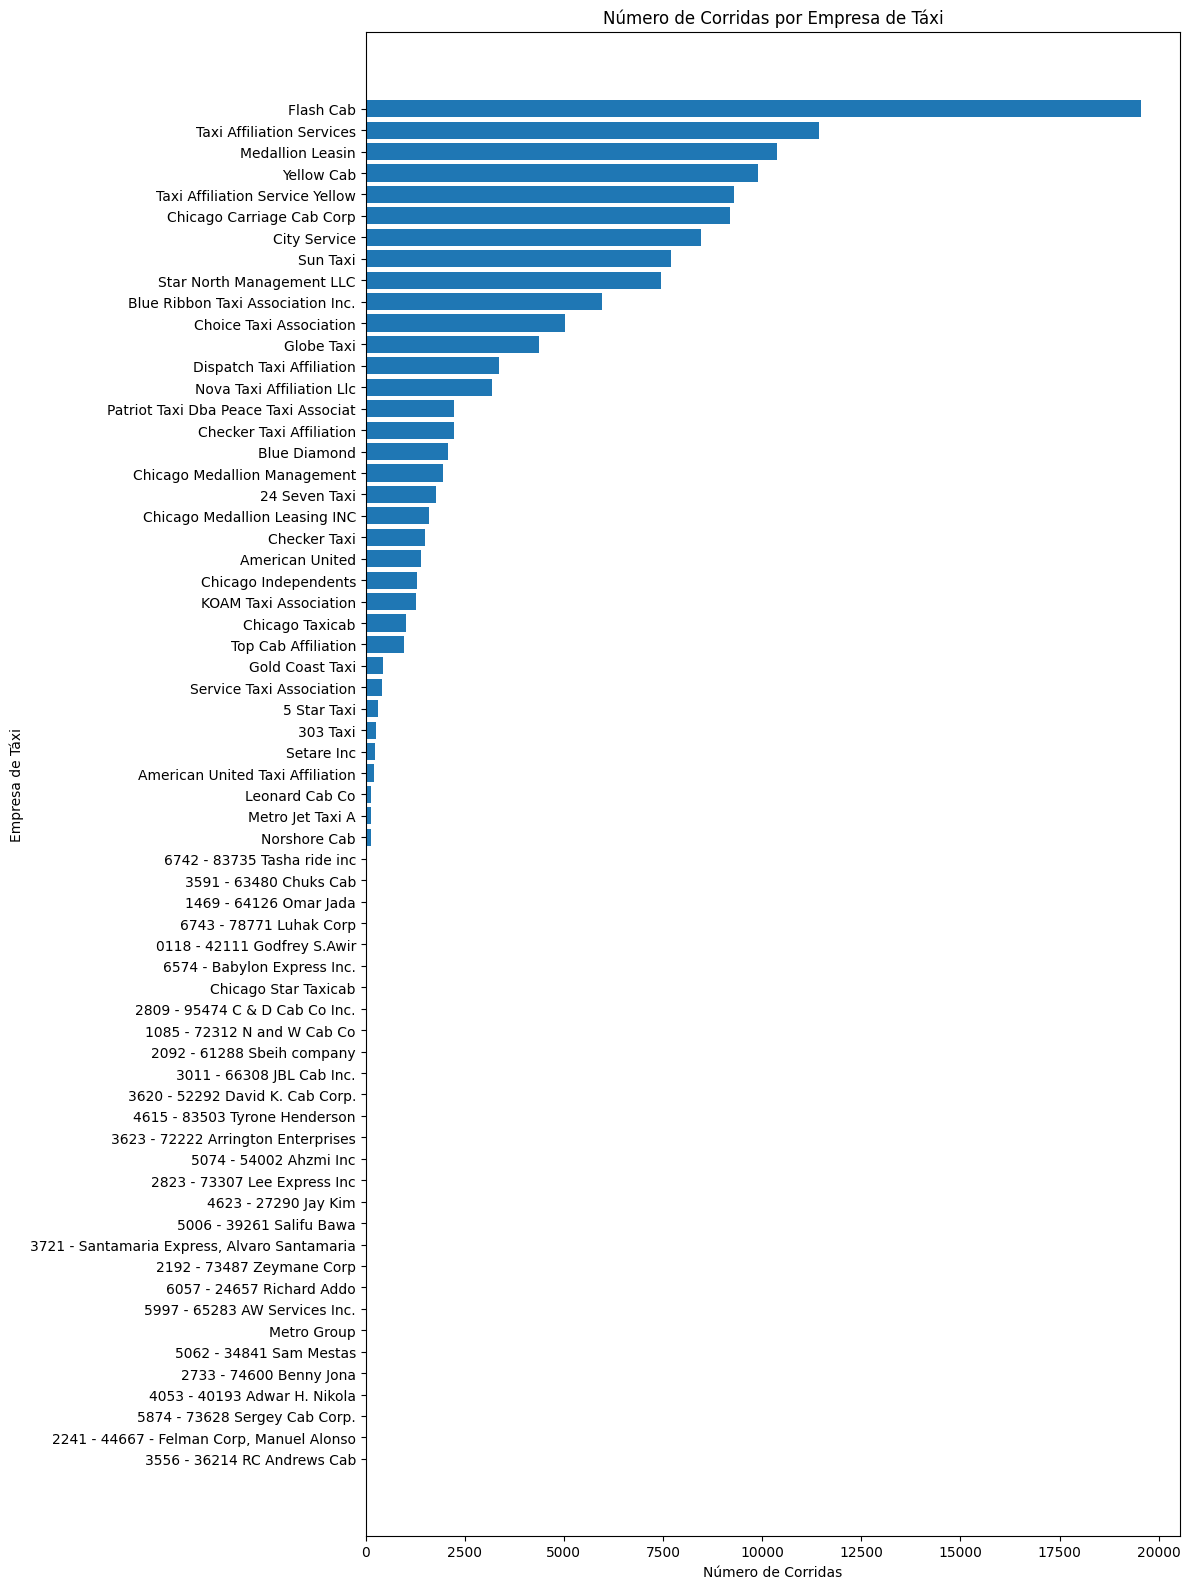

In [58]:
# Ordenar as empresas pelo número de corridas
companies_sorted = df_companies.sort_values(
    by="trips_amount",
    ascending=True
)

# Criar gráfico de barras horizontais
plt.figure(figsize=(12, 16))

plt.barh(
    companies_sorted["company_name"],
    companies_sorted["trips_amount"]
)

plt.title("Número de Corridas por Empresa de Táxi")
plt.xlabel("Número de Corridas")
plt.ylabel("Empresa de Táxi")

plt.tight_layout()
plt.show()

**Análise do Gráfico**

O gráfico demonstra uma distribuição desigual do número de corridas entre as 64 empresas de táxi analisadas, no período de 15 a 16 de novembro de 2017.

A Flash Cab apresentou o maior volume, com 19.558 corridas, seguida pela Taxi Affiliation Services, com 11.422. A diferença de 8.136 corridas entre as duas empresas evidencia a liderança expressiva da Flash Cab.

Na sequência, destacam-se Medallion Leasin, com 10.367 corridas, Yellow Cab, com 9.888, e Taxi Affiliation Service Yellow, com 9.299.

Também é possível observar que poucas empresas concentram volumes elevados de corridas, enquanto a maioria apresenta números consideravelmente menores.

Esse cenário evidencia uma distribuição desigual da atividade entre as empresas de táxi, com destaque para a participação da Flash Cab no período analisado.

## **3.4 — Gráfico dos 10 principais bairros**

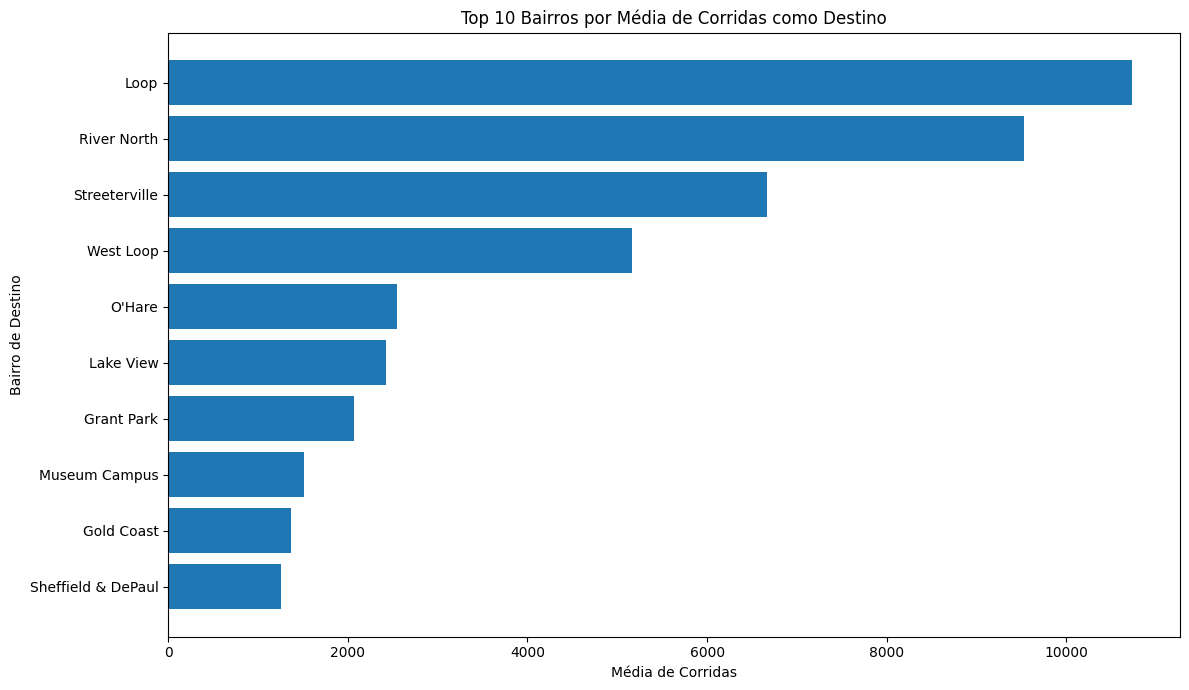

In [59]:
# Ordenar os bairros pela média de corridas
neighborhoods_sorted = top_10_neighborhoods.sort_values(
    by="average_trips",
    ascending=True
)

# Criar gráfico de barras horizontais
plt.figure(figsize=(12, 7))

plt.barh(
    neighborhoods_sorted["dropoff_location_name"],
    neighborhoods_sorted["average_trips"]
)

plt.title("Top 10 Bairros por Média de Corridas como Destino")
plt.xlabel("Média de Corridas")
plt.ylabel("Bairro de Destino")

plt.tight_layout()
plt.show()

**Análise do Gráfico**

O gráfico apresenta os dez bairros de Chicago com as maiores médias de corridas recebidas como destino durante novembro de 2017.

O bairro Loop lidera o ranking, com uma média de aproximadamente 10.727 corridas, seguido por River North, com 9.524, e Streeterville, com 6.665.

West Loop ocupa a quarta posição, com aproximadamente 5.164 corridas. A partir desse bairro, observa-se uma redução significativa nas médias, especialmente entre West Loop e O'Hare.

Os resultados demonstram uma concentração de destinos nos bairros Loop e River North, que apresentam médias consideravelmente superiores às dos demais bairros analisados.

## **3.5. Conclusão da Análise Exploratória**

A análise dos dados revelou diferenças significativas tanto no volume de corridas entre as empresas de táxi quanto na distribuição dos destinos em Chicago.

Entre as empresas, a Flash Cab apresentou o maior número de corridas no período de 15 a 16 de novembro de 2017, com 19.558 registros, destacando-se em relação às demais concorrentes.

Quanto aos bairros de destino, Loop e River North lideraram o ranking de novembro de 2017, com médias de aproximadamente 10.727 e 9.524 corridas, respectivamente.

Esses resultados permitem identificar as empresas com maior volume de operações e os bairros com maior concentração de chegadas, oferecendo uma visão inicial da dinâmica do mercado de táxis em Chicago.

# **4. Análise Comparativa do Clima (Python)**

Nesta etapa, será realizada uma análise comparativa da duração das corridas de táxi entre o bairro Loop e o aeroporto O'Hare, considerando as condições meteorológicas aos sábados de novembro de 2017.

O objetivo é comparar a duração média das viagens em condições climáticas adversas (`Bad`) e não adversas (`Good`), utilizando os resultados da consulta SQL anterior.

A análise será realizada com Python e Pandas, seguida de uma visualização gráfica para facilitar a comparação dos resultados.

## **4.1. Preparação e inspeção dos dados**

Nesta etapa, será utilizado o conjunto de dados resultante da última consulta SQL, contendo 200 registros de corridas realizadas aos sábados entre o bairro Loop e o aeroporto O'Hare, em Chicago, durante novembro de 2017.

Os dados apresentam três variáveis: data e horário de início da corrida (`start_ts`), condições meteorológicas (`weather_conditions`) e duração da viagem em segundos (`duration_seconds`).

Como os registros já foram obtidos e organizados na etapa anterior, não será necessário executar novamente a consulta SQL. Inicialmente, será realizada uma inspeção da estrutura dos dados, dos tipos de variáveis, da existência de valores ausentes e da distribuição das categorias meteorológicas, garantindo que o conjunto esteja adequado para a análise comparativa.

In [61]:
# Verificar as primeiras linhas do conjunto de dados (usando result_6)
display(result_6.head())

# Verificar dimensões do conjunto de dados
print("Dimensões:", result_6.shape)

# Verificar tipos de dados e valores não nulos
result_6.info()

# Verificar valores ausentes
display(result_6.isnull().sum())

# Verificar as categorias meteorológicas existentes
display(result_6["weather_conditions"].value_counts())

,start_ts,weather_conditions,duration_seconds
0,2017-11-25 12:00:00,Good,1380
1,2017-11-25 16:00:00,Good,2410
2,2017-11-25 14:00:00,Good,1920
3,2017-11-25 12:00:00,Good,1543
4,2017-11-04 10:00:00,Good,2512


Dimensões: (200, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            200 non-null    datetime64[ns]
 1   weather_conditions  200 non-null    object        
 2   duration_seconds    200 non-null    int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 4.8+ KB


,0
start_ts,0
weather_conditions,0
duration_seconds,0


,count
weather_conditions,
Good,174
Bad,26


**Análise da inspeção dos dados**

O conjunto de dados contém 200 registros e três colunas: `start_ts`, `weather_conditions` e `duration_seconds`.

A verificação dos tipos de dados demonstrou que as variáveis estão adequadamente formatadas: `start_ts` está no formato de data e hora (`datetime64[ns]`), `weather_conditions` como texto (`object`) e `duration_seconds` como número inteiro (`int64`).

Não foram identificados valores ausentes em nenhuma das colunas.

Em relação às condições meteorológicas, foram registrados 174 viagens em condições favoráveis (`Good`), correspondentes a 87% do conjunto, e 26 viagens em condições adversas (`Bad`), representando 13%.

Dessa forma, os dados estão estruturados adequadamente para a comparação da duração média das corridas entre as duas categorias meteorológicas.

## **4.2. Cálculo da duração média das corridas por condição climática**

In [63]:
# Calcular a duração média das corridas para cada condição meteorológica (usando result_6)
average_duration = (
    result_6
    .groupby("weather_conditions")["duration_seconds"]
    .mean()
    .reset_index()
)

# Converter a duração média de segundos para minutos
average_duration["average_duration_minutes"] = (
    average_duration["duration_seconds"] / 60
)

# Exibir os resultados
display(average_duration)

,weather_conditions,duration_seconds,average_duration_minutes
0,Bad,2459.807692,40.996795
1,Good,1899.471264,31.657854


**Análise dos resultados**

Os resultados demonstram uma diferença na duração média das corridas de acordo com as condições meteorológicas.

Nos sábados com condições climáticas adversas (`Bad`), a duração média das viagens foi de aproximadamente 41 minutos. Já nos sábados com condições não adversas (`Good`), a média foi de aproximadamente 31,66 minutos.

A diferença entre as médias foi de aproximadamente 9,34 minutos, indicando que as corridas realizadas em condições climáticas adversas apresentaram maior duração média.

Esses resultados sugerem uma associação entre as condições meteorológicas e o tempo de deslocamento entre o bairro Loop e o aeroporto O'Hare. Entretanto, a análise não permite afirmar que o clima seja a única causa dessa diferença.

## **4.3. Visualização comparativa**

Elaborar um gráfico de barras para comparar as duas médias.

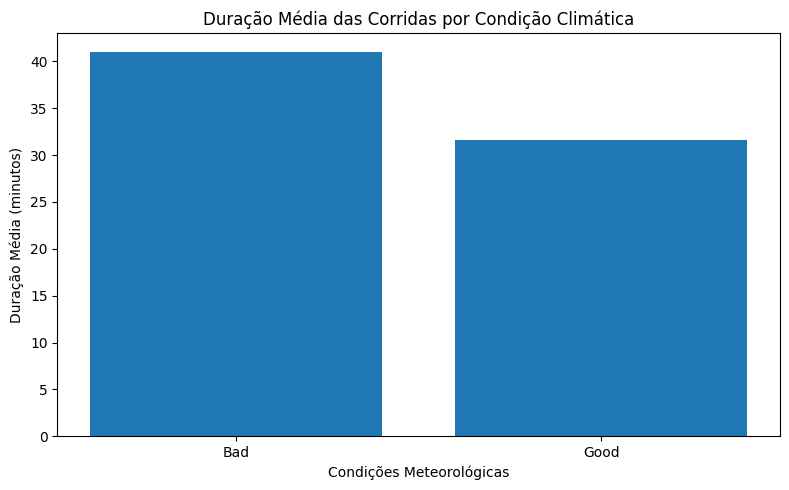

In [64]:
# Criar gráfico de comparação da duração média das corridas
plt.figure(figsize=(8, 5))

plt.bar(
    average_duration["weather_conditions"],
    average_duration["average_duration_minutes"]
)

plt.title("Duração Média das Corridas por Condição Climática")
plt.xlabel("Condições Meteorológicas")
plt.ylabel("Duração Média (minutos)")

plt.tight_layout()
plt.show()

**Análise do gráfico**

O gráfico evidencia uma diferença na duração média das corridas de acordo com as condições meteorológicas.

Em condições adversas (`Bad`), as viagens apresentaram duração média de aproximadamente 41 minutos. Já em condições não adversas (`Good`), a duração média foi de aproximadamente 31,66 minutos.

A diferença de aproximadamente 9,34 minutos indica que as corridas realizadas em sábados com chuva ou tempestade tiveram maior duração média do que aquelas realizadas em condições meteorológicas favoráveis.

Essa diferença sugere que condições climáticas adversas podem estar associadas ao aumento do tempo de deslocamento entre Loop e O'Hare.

## **4.4. Conclusão da Análise Comparativa do Clima**

A análise comparativa demonstrou que as condições meteorológicas estão associadas a diferenças na duração média das corridas entre o bairro Loop e o aeroporto O'Hare.

Nos sábados classificados como `Bad`, a duração média foi de aproximadamente 41 minutos, enquanto nos sábados classificados como `Good`, foi de aproximadamente 31,66 minutos.

Portanto, as viagens realizadas sob condições climáticas adversas apresentaram duração média cerca de 29,5% maior em comparação às viagens realizadas em condições não adversas.

Os resultados sugerem que chuva e tempestades podem contribuir para o aumento do tempo de deslocamento, possivelmente devido a fatores como redução da velocidade do tráfego e condições menos favoráveis de circulação.

Entretanto, como a análise considera apenas a associação entre as condições meteorológicas e a duração das viagens, não é possível estabelecer uma relação de causalidade definitiva.

# **5. CONCLUSÃO GERAL**

O desenvolvimento deste projeto permitiu explorar dados do mercado de táxis de Chicago, identificar padrões no volume de corridas por empresa e por bairro de destino e investigar a relação entre as condições meteorológicas e a duração das viagens.

Na análise das empresas, a Flash Cab destacou-se pelo maior volume de corridas, com 19.558 registros entre 15 e 16 de novembro de 2017. Na comparação realizada entre 1º e 7 de novembro, a categoria "Other", que reúne as demais empresas, concentrou o maior volume de viagens, seguida pela Flash Cab e pela Taxi Affiliation Services. Esses resultados demonstram a relevância de analisar tanto o desempenho individual das empresas quanto a distribuição geral do mercado.

Em relação aos destinos, Loop e River North apresentaram as maiores médias de corridas em novembro de 2017, com aproximadamente 10.727 e 9.524 viagens, respectivamente. Essa concentração evidencia a importância desses bairros na dinâmica de deslocamento de passageiros em Chicago.

Na análise comparativa das condições meteorológicas, foram avaliadas 200 corridas realizadas aos sábados entre Loop e o aeroporto O'Hare. As viagens classificadas como `Bad` apresentaram duração média de aproximadamente 41 minutos, enquanto aquelas classificadas como `Good` registraram média de 31,66 minutos. A diferença de aproximadamente 9,34 minutos indica que as condições climáticas adversas estão associadas a viagens mais longas no trajeto analisado.

De forma geral, o projeto demonstrou como a utilização integrada de SQL e Python permite consultar, organizar, explorar e interpretar grandes conjuntos de dados, transformando registros operacionais em informações relevantes para a análise de mercado e identificação de padrões.

Os resultados oferecem uma visão sobre o comportamento do mercado de táxis em Chicago e destacam a importância de considerar fatores geográficos e meteorológicos na análise das operações de transporte. Entretanto, as conclusões são descritivas e estão limitadas aos períodos e dados disponibilizados, não permitindo estabelecer relações de causalidade ou generalizar os resultados para todo o mercado.